# Capítulo 5 · Selección de características y comparación de modelos

**Aprendizaje supervisado · ¿Necesitamos todas las variables?**

Seleccionar características significa **conservar algunas columnas originales** y retirar otras.
Buscamos un modelo más sencillo que mantenga un desempeño útil; quitar columnas no garantiza mejorar las predicciones.
No es lo mismo que PCA, que construye nuevas variables combinando las originales.

Trabajaremos con **Wine**, incluido en scikit-learn: 178 muestras, 13 mediciones químicas
y tres clases que representan cultivares de vino. Predeciremos la clase, no la calidad ni el precio.
Hay suficientes columnas para comparar técnicas y pocas filas para que las búsquedas sean manejables.
No hace falta descargar archivos ni conectarse a Internet.

### Objetivos

- Distinguir filtros, métodos de búsqueda e integrados.
- Aplicar cada técnica y ver qué columnas conserva.
- Comparar las columnas elegidas por cada técnica.
- Entrenar distintos modelos con cada subconjunto y con todas las columnas.
- Elegir con validación cruzada en train y evaluar una sola vez en test.

### Índice

Preparación común: diagnóstico, limpieza y partición de datos.

1. Filtro de varianza
2. Filtro de correlación entre características
3. Selección univariada: ANOVA
4. Selección hacia adelante (*forward selection*)
5. Selección hacia atrás (*backward elimination*)
6. Eliminación recursiva: RFE
7. Selección con Lasso
8. Extensión: búsqueda exhaustiva

9. Comparar las características seleccionadas
10. Entrenar SVC, regresión logística y Random Forest

Cierre: evaluación final y preguntas para discutir.
La búsqueda exhaustiva puede revisarse en una segunda sesión.

Fuente del dataset: [Wine en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html).

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import (
    RFE, SelectKBest, SequentialFeatureSelector,
    VarianceThreshold, f_classif,
)
from sklearn.linear_model import Lasso, LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [2]:
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
N_FEATURES = 6

---
## Preparación común

### Diagnóstico y limpieza simple

In [3]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
df.shape

(178, 14)

In [5]:
df.dtypes

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

In [6]:
df.isna().sum()

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

In [7]:
np.isinf(df).sum()

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

Aplicamos la limpieza en pasos separados. En Wine no se pierden filas porque ya está limpio.

In [9]:
df = df.replace([np.inf, -np.inf], np.nan)

In [10]:
df = df.drop_duplicates()

In [11]:
df = df.dropna()
df.shape

(178, 14)

### Entrenamiento y prueba: 80-20

Hacemos una sola división:

- **80 % para entrenamiento:** explorar, seleccionar características, entrenar y comparar candidatos.
- **20 % para prueba (test):** evaluar el modelo elegido al final.

`test_size=0.2` reserva el 20 % para test. `stratify=y` mantiene aproximadamente la proporción
de las clases y `random_state=42` permite repetir la partición.
La columna `target` es la respuesta y no se incluye entre las características.

La búsqueda de hiperparámetros usará tres particiones de validación cruzada dentro del 80 % de train.
No creamos un conjunto de validación separado. Test queda fuera de todas las decisiones.

In [12]:
X = df.drop(columns="target")
y = df["target"].astype(int)

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE,
)

In [14]:
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (142, 13)
Prueba: (36, 13)


In [15]:
y_train.value_counts().sort_index()

target
0    47
1    57
2    38
Name: count, dtype: int64

In [16]:
X_train.describe().T[["min", "mean", "std", "max"]].round(2)

,min,mean,std,max
alcohol,11.03,12.97,0.80,14.83
malic_acid,0.74,2.34,1.10,5.80
ash,1.36,2.36,0.27,3.22
alcalinity_of_ash,10.60,19.63,3.38,30.00
magnesium,70.00,99.63,14.94,162.00
total_phenols,0.98,2.27,0.62,3.88
flavanoids,0.34,1.99,0.95,3.74
nonflavanoid_phenols,0.13,0.36,0.12,0.63
proanthocyanins,0.42,1.60,0.58,3.58
color_intensity,1.28,4.99,2.33,13.00


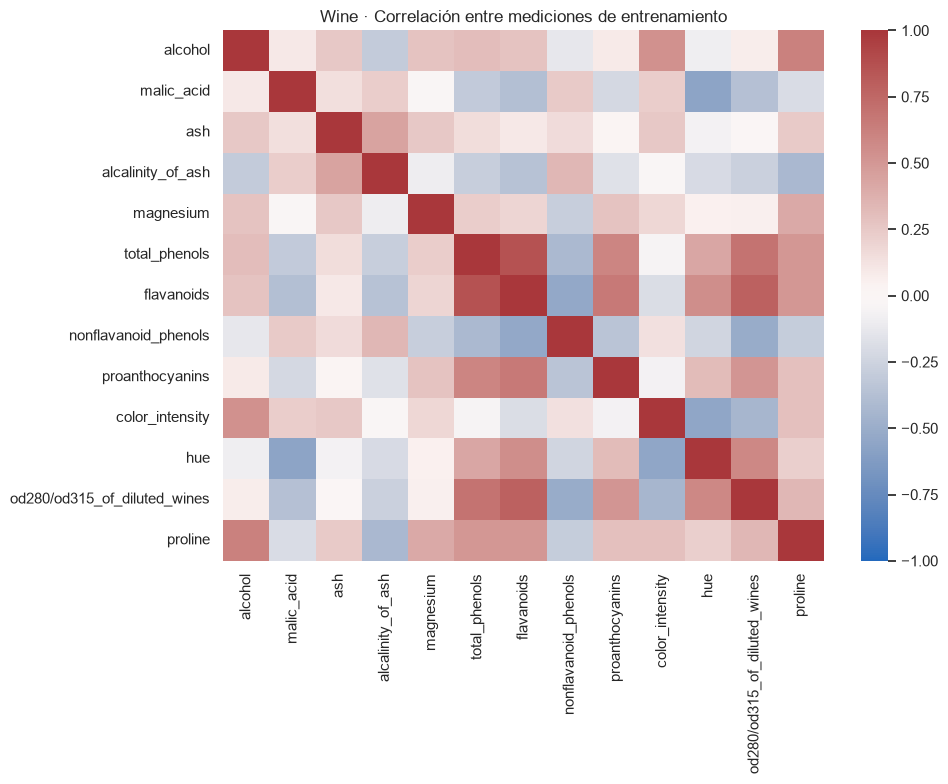

In [17]:
plt.figure(figsize=(10, 8))
sns.heatmap(X_train.corr(), cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Wine · Correlación entre mediciones de entrenamiento")
plt.tight_layout()
plt.show()

In [18]:
selected_columns_all = X_train.columns.tolist()
selected_columns_all

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

---
## 1. Filtro de varianza

**Idea:** una columna que siempre tiene el mismo valor no ayuda a distinguir unas muestras de otras.
`VarianceThreshold(threshold=0)` elimina exclusivamente columnas constantes, sin consultar `y`.

Usamos el umbral cero porque las mediciones tienen unidades distintas: comparar directamente sus
varianzas con un umbral positivo puede confundir escala con información. El filtro va antes del escalado.
Wine no tiene columnas constantes; esperamos conservar las 13. No necesitamos forzar una eliminación.

**Límite:** poca variación no significa necesariamente poca utilidad predictiva.

Referencia: [VarianceThreshold](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.VarianceThreshold.html).

In [19]:
variance_selector = VarianceThreshold(threshold=0)

In [20]:
variance_selector.fit(X_train)

VarianceThreshold(threshold=0)

In [21]:
selected_columns_variance = X_train.columns[variance_selector.get_support()].tolist()
selected_columns_variance

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

---
## 2. Filtro de correlación entre características

**Idea:** si dos columnas se parecen mucho, probamos conservar solo una.
Usamos la correlación de Pearson **entre características**, no entre las características y la clase numérica.
El signo no cambia la redundancia: una correlación de -0.95 también es fuerte, por eso tomamos el valor absoluto.

Regla de esta práctica: recorrer las columnas en su orden original y conservar una si su correlación
absoluta con todas las ya conservadas es menor que 0.85. El orden y el umbral influyen en el resultado.
No demuestra que la columna descartada sea inútil ni detecta todas las relaciones no lineales.

In [22]:
correlation = X_train.corr().abs()
correlation.round(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
alcohol,1.00,0.10,0.25,0.30,0.28,0.31,0.27,0.13,0.09,0.54,0.09,0.08,0.62
malic_acid,0.10,1.00,0.14,0.23,0.03,0.31,0.38,0.24,0.22,0.23,0.57,0.37,0.20
ash,0.25,0.14,1.00,0.44,0.25,0.15,0.10,0.16,0.02,0.25,0.06,0.01,0.25
alcalinity_of_ash,0.30,0.23,0.44,1.00,0.10,0.29,0.36,0.34,0.17,0.02,0.20,0.27,0.43
magnesium,0.28,0.03,0.25,0.10,1.00,0.23,0.19,0.29,0.28,0.19,0.05,0.06,0.41
total_phenols,0.31,0.31,0.15,0.29,0.23,1.00,0.86,0.42,0.60,0.05,0.42,0.69,0.51
flavanoids,0.27,0.38,0.10,0.36,0.19,0.86,1.00,0.53,0.66,0.19,0.55,0.79,0.51
nonflavanoid_phenols,0.13,0.24,0.16,0.34,0.29,0.42,0.53,1.00,0.35,0.13,0.24,0.51,0.30
proanthocyanins,0.09,0.22,0.02,0.17,0.28,0.60,0.66,0.35,1.00,0.07,0.32,0.51,0.30
color_intensity,0.54,0.23,0.25,0.02,0.19,0.05,0.19,0.13,0.07,1.00,0.55,0.44,0.29


Recorremos las columnas. Conservamos una columna si todas sus correlaciones con las ya elegidas
son menores que 0.85. `.all()` comprueba que se cumpla para todas; al principio la lista está vacía
y se conserva la primera columna.

In [23]:
selected_columns_correlation = []

for column in X_train.columns:
    correlations = correlation.loc[column, selected_columns_correlation]
    if (correlations < 0.85).all():
        selected_columns_correlation.append(column)

In [24]:
selected_columns_correlation

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

---
## 3. Selección univariada: ANOVA

**Idea:** evaluar cada característica por separado y conservar las seis con mayor puntuación.
`f_classif` compara cuánto cambian las medias de una medición entre clases frente a su variación dentro de las clases.
Una puntuación F mayor sugiere más separación entre grupos para esa medición.

`SelectKBest` ordena esas puntuaciones y conserva las primeras `k`.
Aquí lo usamos como filtro exploratorio; no interpretaremos sus p-valores como evidencia científica.

**Límite:** dos variables pueden ser útiles juntas aunque ninguna destaque por separado.
También puede conservar varias columnas redundantes porque no compara unas características con otras.

Referencia: [SelectKBest](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html).

In [25]:
anova_selector = SelectKBest(score_func=f_classif, k=N_FEATURES)

In [26]:
anova_selector.fit(X_train, y_train)

SelectKBest(k=6)

In [27]:
selected_columns_anova = X_train.columns[anova_selector.get_support()].tolist()
selected_columns_anova

['alcohol',
 'flavanoids',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

In [28]:
anova_scores = pd.Series(anova_selector.scores_, index=X_train.columns)
anova_scores.sort_values(ascending=False)

flavanoids                      224.760551
proline                         161.459538
od280/od315_of_diluted_wines    144.758527
color_intensity                 103.897340
alcohol                          98.468093
hue                              79.531558
total_phenols                    72.338568
malic_acid                       29.088066
alcalinity_of_ash                27.518692
proanthocyanins                  23.347278
nonflavanoid_phenols             20.767530
ash                              12.856907
magnesium                         9.237633
dtype: float64

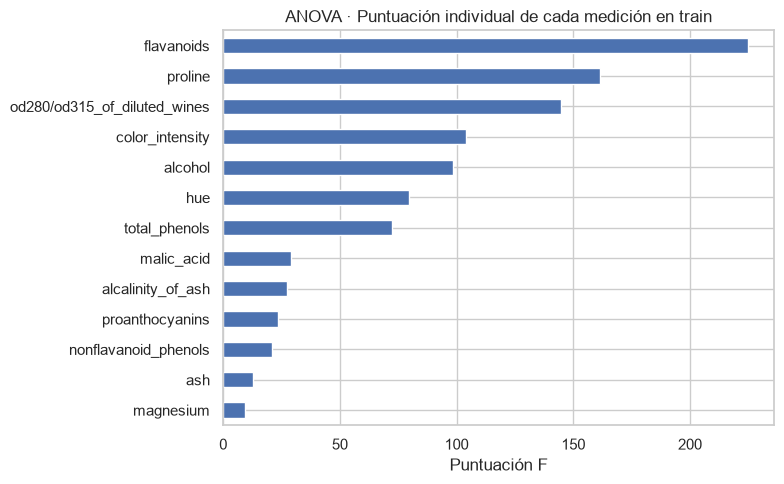

In [29]:
anova_scores.sort_values().plot.barh(figsize=(8, 5))
plt.title("ANOVA · Puntuación individual de cada medición en train")
plt.xlabel("Puntuación F")
plt.tight_layout()
plt.show()

---
## 4. Selección hacia adelante · Forward selection

El selector empieza con la columna que obtiene la mayor accuracy media en validación cruzada. Luego prueba añadir cada una de las restantes. Acepta la mejor incorporación si la accuracy aumenta al menos `1e-6`. Cuando la mejora queda por debajo de ese valor, se detiene.

La cantidad de columnas se decide durante el ajuste con `n_features_to_select="auto"` y `tol`. [Documentación de SequentialFeatureSelector](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SequentialFeatureSelector.html).

Preparamos el SVC que evaluará los subconjuntos y tres particiones de entrenamiento.
Esta validación cruzada es **interna al selector**; solo usa `X_train` e `y_train`; no usa test.
El pipeline ajusta el escalado dentro de cada partición interna.

In [30]:
selection_model = Pipeline([
    ("scale", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=1)),
])

In [31]:
selection_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE,
)

In [32]:
forward_selector = SequentialFeatureSelector(
    selection_model,
    n_features_to_select="auto",
    tol=1e-6,
    direction="forward",
    scoring="accuracy",
    cv=selection_cv,
)

In [33]:
forward_selector.fit(X_train, y_train)

,estimator estimator: estimator instanceAn unfitted estimator.,"Pipeline(step...', SVC(C=1))])"
,"tol tol: float, default=NoneIf the score is not incremented by at least `tol` between twoconsecutive feature additions or removals, stop adding or removing.`tol` can be negative when removing features using `direction=""backward""`.`tol` is required to be strictly positive when doing forward selection.It can be useful to reduce the number of features at the cost of a smalldecrease in the score.`tol` is enabled only when `n_features_to_select` is `""auto""`... versionadded:: 1.1",1e-06
,"scoring scoring: str or callable, default=NoneScoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)`` that returns a single value. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. In all othercases, :class:`~sklearn.model_selection.KFold` is used. These splittersare instantiated with `shuffle=False` so the splits will be the sameacross calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",StratifiedKFo... shuffle=True)
,"n_features_to_select n_features_to_select: ""auto"", int or float, default=""auto""If `""auto""`, the behaviour depends on the `tol` parameter:- if `tol` is not `None`, then features are selected while the score change does not exceed `tol`.- otherwise, half of the features are selected.If integer, the parameter is the absolute number of features to select.If float between 0 and 1, it is the fraction of features to select... versionadded:: 1.1 The option `""auto""` was added in version 1.1... versionchanged:: 1.3 The default changed from `""warn""` to `""auto""` in 1.3.",'auto'
,"direction direction: {'forward', 'backward'}, default='forward'Whether to perform forward selection or backward selection.",'forward'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel. When evaluating a new feature toadd or remove, the cross-validation procedure is parallel over thefolds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['alcohol','malic_acid','ash',...,'hue','od280/od315_of_diluted_wines', 'proline']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,13
n_features_to_select_ n_features_to_select_: intThe number of features that were selected.,int64,np.int64(5)


In [34]:
selected_columns_forward = X_train.columns[forward_selector.get_support()].tolist()
selected_columns_forward

['alcohol', 'alcalinity_of_ash', 'flavanoids', 'color_intensity', 'proline']

---
## 5. Selección hacia atrás · Backward elimination

El selector parte de las 13 columnas y elige la primera que puede retirar con la mayor accuracy media en validación cruzada. Ese resultado es su referencia para el siguiente paso.

Con `tol=0.0`, sigue retirando una columna por paso mientras la accuracy se mantenga o mejore. Si todas las eliminaciones posibles reducen la puntuación respecto al paso anterior, se detiene.

In [35]:
backward_selector = SequentialFeatureSelector(
    selection_model,
    n_features_to_select="auto",
    tol=0.0,
    direction="backward",
    scoring="accuracy",
    cv=selection_cv,
)

In [36]:
backward_selector.fit(X_train, y_train)

,estimator estimator: estimator instanceAn unfitted estimator.,"Pipeline(step...', SVC(C=1))])"
,"tol tol: float, default=NoneIf the score is not incremented by at least `tol` between twoconsecutive feature additions or removals, stop adding or removing.`tol` can be negative when removing features using `direction=""backward""`.`tol` is required to be strictly positive when doing forward selection.It can be useful to reduce the number of features at the cost of a smalldecrease in the score.`tol` is enabled only when `n_features_to_select` is `""auto""`... versionadded:: 1.1",0.0
,"direction direction: {'forward', 'backward'}, default='forward'Whether to perform forward selection or backward selection.",'backward'
,"scoring scoring: str or callable, default=NoneScoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)`` that returns a single value. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. In all othercases, :class:`~sklearn.model_selection.KFold` is used. These splittersare instantiated with `shuffle=False` so the splits will be the sameacross calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",StratifiedKFo... shuffle=True)
,"n_features_to_select n_features_to_select: ""auto"", int or float, default=""auto""If `""auto""`, the behaviour depends on the `tol` parameter:- if `tol` is not `None`, then features are selected while the score change does not exceed `tol`.- otherwise, half of the features are selected.If integer, the parameter is the absolute number of features to select.If float between 0 and 1, it is the fraction of features to select... versionadded:: 1.1 The option `""auto""` was added in version 1.1... versionchanged:: 1.3 The default changed from `""warn""` to `""auto""` in 1.3.",'auto'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel. When evaluating a new feature toadd or remove, the cross-validation procedure is parallel over thefolds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['alcohol','malic_acid','ash',...,'hue','od280/od315_of_diluted_wines', 'proline']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,13
n_features_to_select_ n_features_to_select_: intThe number of features that were selected.,int64,np.int64(8)


In [37]:
selected_columns_backward = X_train.columns[backward_selector.get_support()].tolist()
selected_columns_backward

['malic_acid',
 'ash',
 'alcalinity_of_ash',
 'flavanoids',
 'nonflavanoid_phenols',
 'color_intensity',
 'od280/od315_of_diluted_wines',
 'proline']

Comparamos las listas. Convertirlas a `set` permite ver sus coincidencias y diferencias.

In [38]:
print("En ambos:", sorted(set(selected_columns_forward) & set(selected_columns_backward)))
print("Solo forward:", sorted(set(selected_columns_forward) - set(selected_columns_backward)))
print("Solo backward:", sorted(set(selected_columns_backward) - set(selected_columns_forward)))

En ambos: ['alcalinity_of_ash', 'color_intensity', 'flavanoids', 'proline']
Solo forward: ['alcohol']
Solo backward: ['ash', 'malic_acid', 'nonflavanoid_phenols', 'od280/od315_of_diluted_wines']


---
## 6. Eliminación recursiva · RFE

**Idea:** entrenar un modelo, retirar la variable con menor peso y volver a entrenar hasta conservar seis.

Backward prueba cada posible eliminación con validación; **RFE utiliza los pesos del modelo ajustado**.
Por eso suele necesitar menos entrenamientos.

El SVC con RBF no tiene un coeficiente por característica. Usaremos un **SVC lineal para seleccionar**,
que sí tiene `coef_`. Guardaremos sus columnas para la comparación final de modelos.
Primero estandarizamos las mediciones usando únicamente train para que sus pesos sean comparables.
En multiclase, RFE combina los coeficientes al cuadrado al ordenar las variables.

**Límite:** una variable poco útil para una frontera lineal podría ser útil para una no lineal.

Referencia: [RFE](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html).

In [39]:
selection_scaler = StandardScaler()
X_train_scaled = selection_scaler.fit_transform(X_train)

In [40]:
rfe_selector = RFE(
    estimator=SVC(kernel="linear", C=1),
    n_features_to_select=N_FEATURES,
    step=1,
)

In [41]:
rfe_selector.fit(X_train_scaled, y_train)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).","SVC(C=1, kernel='linear')"
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",6
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[int64](3,)","[0,1,2]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,SVC,"SVC(C=1, kernel='linear')"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(6)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,13
"ranking_ ranking_: ndarray of shape (n_features,)The feature ranking, such that ``ranking_[i]`` corresponds to theranking position of the i-th feature. Selected (i.e., estimatedbest) features are assigned rank 1.","ndarray[int64](13,)","[1,5,2,...,1,1,1]"


In [42]:
selected_columns_rfe = X_train.columns[rfe_selector.get_support()].tolist()
selected_columns_rfe

['alcohol',
 'flavanoids',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

El rango `1` identifica las variables conservadas. Los demás rangos corresponden a variables descartadas.

In [43]:
rfe_ranking = pd.Series(rfe_selector.ranking_, index=X_train.columns)
rfe_ranking.sort_values()

alcohol                         1
flavanoids                      1
hue                             1
color_intensity                 1
proline                         1
od280/od315_of_diluted_wines    1
ash                             2
alcalinity_of_ash               3
proanthocyanins                 4
malic_acid                      5
total_phenols                   6
magnesium                       7
nonflavanoid_phenols            8
dtype: int64

## 7. Selección con Lasso

Lasso es una regresión que puede llevar algunos coeficientes a cero. Usaremos las mediciones estandarizadas de entrenamiento. Fijamos `alpha=0.05` para este ejemplo. Un valor mayor penaliza más los coeficientes.

Wine tiene tres clases. Para cada una creamos una columna que vale 1 cuando la muestra pertenece a esa clase y 0 en los demás casos. Así Lasso ajusta una regresión por clase y podemos ver qué mediciones tienen peso en cada una.

In [44]:
class_indicators = pd.get_dummies(y_train, prefix="clase", dtype=int)
class_indicators.head()

,clase_0,clase_1,clase_2
36,1,0,0
30,1,0,0
26,1,0,0
12,1,0,0
148,0,0,1


In [45]:
lasso = Lasso(alpha=0.05)
lasso.fit(X_train_scaled, class_indicators)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.05
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [46]:
lasso_weights = pd.DataFrame(lasso.coef_, index=class_indicators.columns, columns=X_train.columns)
lasso_weights.T

,clase_0,clase_1,clase_2
alcohol,0.079349,-0.116405,0.000000
malic_acid,0.000000,-0.067329,0.044621
ash,0.000000,-0.030600,0.003537
alcalinity_of_ash,-0.030434,0.000000,0.000000
magnesium,0.000000,-0.000000,0.000000
total_phenols,0.000000,0.000000,-0.000000
flavanoids,0.124330,0.000000,-0.179162
nonflavanoid_phenols,-0.000000,-0.000000,0.000000
proanthocyanins,-0.000000,0.023306,-0.000000
color_intensity,0.000000,-0.167356,0.131714


Conservamos una característica si su coeficiente es distinto de cero en al menos una clase. En la siguiente celda, `.any()` comprueba esa condición para cada característica.

In [47]:
keep = (lasso_weights != 0).any()
selected_columns_lasso = X_train.columns[keep].tolist()
selected_columns_lasso

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'flavanoids',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

---
## 8. Extensión: búsqueda exhaustiva

**Idea:** probar todos los subconjuntos no vacíos de las columnas candidatas.
Con `p` columnas existen `2**p - 1` subconjuntos. Con las 13 de Wine serían 8191,
y cada uno necesita varios entrenamientos para evaluarse.

Para mostrarlo de forma rápida declaramos cinco candidatas: alcohol, ácido málico, flavonoides,
intensidad de color y prolina. Probamos sus 31 subconjuntos con el SVC fijo y validación cruzada sobre train.
Las candidatas se fijaron de antemano, sin consultar test.

La búsqueda es exhaustiva **solo entre esas cinco columnas y para ese SVC fijo**.
Su espacio de búsqueda es distinto del de los métodos que consideran las 13 variables.

In [48]:
def subset_accuracy(columns):
    scores = cross_val_score(
        selection_model, X_train[columns], y_train,
        cv=selection_cv, scoring="accuracy",
    )
    return scores.mean()

In [49]:
exhaustive_candidates = [
    "alcohol", "malic_acid", "flavanoids", "color_intensity", "proline",
]
2 ** len(exhaustive_candidates) - 1

31

`combinations` construye los grupos de una, dos, tres, cuatro y cinco columnas.
Guardamos su puntuación para poder ver la tabla de resultados.

In [50]:
exhaustive_results = []

for size in range(1, len(exhaustive_candidates) + 1):
    for subset in combinations(exhaustive_candidates, size):
        columns = list(subset)
        score = subset_accuracy(columns)
        exhaustive_results.append({
            "columnas": columns,
            "variables": len(columns),
            "accuracy_cv": score,
        })

In [51]:
exhaustive_table = pd.DataFrame(exhaustive_results)
exhaustive_table = exhaustive_table.sort_values(
    ["accuracy_cv", "variables"], ascending=[False, True],
)
exhaustive_table.head()

,columnas,variables,accuracy_cv
30,"[alcohol, malic_acid, flavanoids, color_intens...",5,0.978871
29,"[malic_acid, flavanoids, color_intensity, prol...",4,0.972074
28,"[alcohol, flavanoids, color_intensity, proline]",4,0.958038
18,"[alcohol, flavanoids, color_intensity]",3,0.957742
25,"[alcohol, malic_acid, flavanoids, color_intens...",4,0.957742


In [52]:
selected_columns_exhaustive = exhaustive_table.iloc[0]["columnas"]
selected_columns_exhaustive

['alcohol', 'malic_acid', 'flavanoids', 'color_intensity', 'proline']

## 9. ¿Qué características eligió cada técnica?

Cada fila de la gráfica representa una medición de Wine. Un cuadro azul indica que el selector de esa columna la conservó. La primera columna muestra la referencia con todas las mediciones.

In [53]:
feature_sets = {
    "Sin selección": selected_columns_all,
    "Varianza cero": selected_columns_variance,
    "Correlación": selected_columns_correlation,
    "ANOVA": selected_columns_anova,
    "Hacia adelante": selected_columns_forward,
    "Hacia atrás": selected_columns_backward,
    "RFE": selected_columns_rfe,
    "Lasso": selected_columns_lasso,
    "Exhaustiva (5 candidatas)": selected_columns_exhaustive,
}

In [54]:
feature_matrix = pd.DataFrame(index=X_train.columns)
for method, columns in feature_sets.items():
    feature_matrix[method] = X_train.columns.isin(columns)

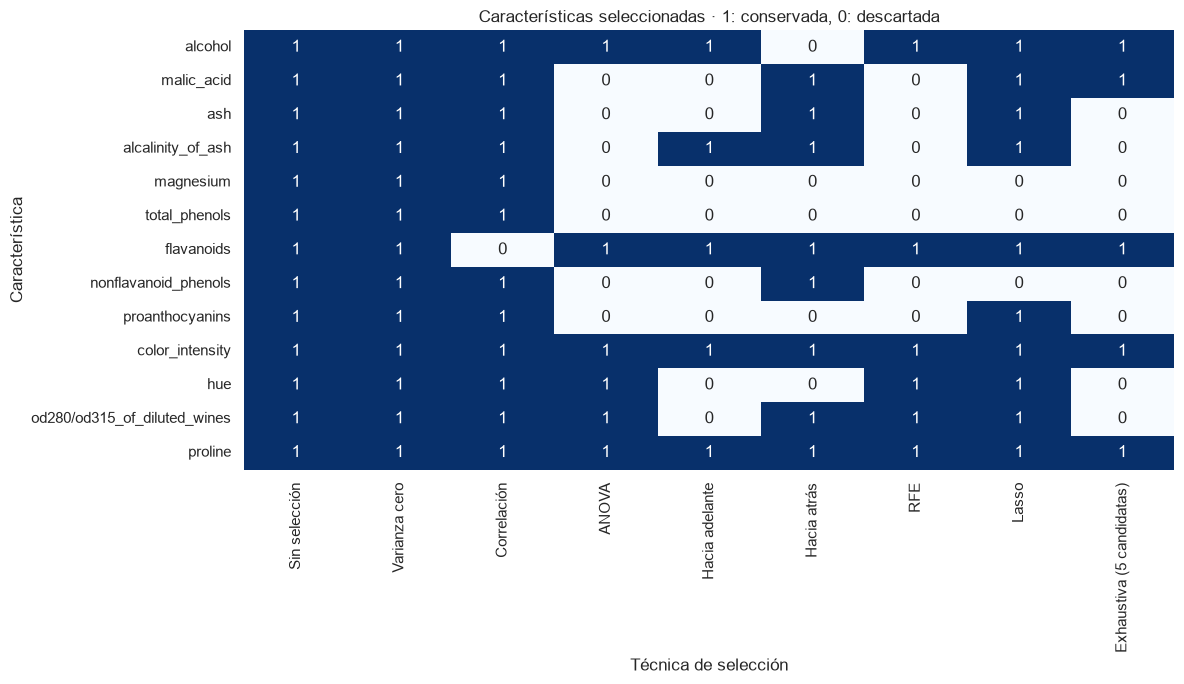

In [55]:
plt.figure(figsize=(12, 7))
sns.heatmap(feature_matrix.astype(int), annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Características seleccionadas · 1: conservada, 0: descartada")
plt.xlabel("Técnica de selección")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

## 10. ¿Qué accuracy obtuvo cada modelo?

Usaremos las mismas tres particiones de entrenamiento para todos los modelos. Probaremos tres valores de `C` para SVC y regresión logística, y tres profundidades para Random Forest. La tabla final mostrará la mejor accuracy media de cada combinación de selector y modelo.

Como las columnas ya se eligieron con todo el entrenamiento, estas puntuaciones pueden ser optimistas. El 20 % de prueba queda reservado para evaluar la combinación elegida.

In [56]:
model_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
c_values = [0.1, 1, 10]

SVC y regresión logística aprenden el escalado dentro de cada partición. Random Forest trabaja directamente con las mediciones.

In [57]:
svc = Pipeline([("escala", StandardScaler()), ("svc", SVC(kernel="rbf"))])
logistic = Pipeline([("escala", StandardScaler()), ("logistic", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
forest = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)

In [58]:
candidates = [
    ("SVC", svc, {"svc__C": c_values}),
    ("Regresión logística", logistic, {"logistic__C": c_values}),
    ("Random Forest", forest, {"max_depth": [3, 5, None]}),
]

Para cada lista de columnas, `GridSearchCV` elige el mejor ajuste de cada modelo usando la accuracy media de validación cruzada.

In [59]:
results = []
trained_models = {}
for selector, columns in feature_sets.items():
    for name, model, grid in candidates:
        search = GridSearchCV(model, grid, cv=model_cv, scoring="accuracy")
        search.fit(X_train[columns], y_train)
        trained_models[(selector, name)] = search.best_estimator_
        results.append({
            "selector": selector, "variables": len(columns), "modelo": name,
            "accuracy_cv": search.best_score_, "parámetros": search.best_params_,
        })

### Comparación de resultados

Cada fila corresponde a un conjunto de columnas. Lee la tabla de arriba abajo para comparar un modelo con su resultado en «Sin selección», o de izquierda a derecha para comparar los tres modelos.

In [60]:
results_table = pd.DataFrame(results)
model_comparison = results_table.pivot(index=["selector", "variables"], columns="modelo", values="accuracy_cv")
model_comparison = model_comparison.reindex(feature_sets.keys(), level="selector")
model_comparison[["SVC", "Regresión logística", "Random Forest"]].round(4)

,modelo,SVC,Regresión logística,Random Forest
selector,variables,,,
Sin selección,13,0.9860,0.9860,0.9511
Varianza cero,13,0.9860,0.9860,0.9511
Correlación,12,0.9860,0.9790,0.9439
ANOVA,6,0.9789,0.9651,0.9369
Hacia adelante,5,0.9861,0.9721,0.9227
Hacia atrás,8,0.9931,0.9931,0.9580
RFE,6,0.9789,0.9651,0.9369
Lasso,10,0.9860,0.9931,0.9440
Exhaustiva (5 candidatas),5,0.9789,0.9790,0.9439


## Evaluación final

Elegimos la mayor accuracy media con los valores completos, antes de redondear. Si hay empate, preferimos el subconjunto con menos variables. Usamos el 20 % de prueba para medir cuántos vinos clasifica correctamente esa combinación.

In [61]:
ranked = results_table.sort_values(["accuracy_cv", "variables"], ascending=[False, True], kind="stable")
best_result = ranked.iloc[0]

In [62]:
winner_selector = best_result["selector"]
winner_name = best_result["modelo"]
winner_columns = feature_sets[winner_selector]
print(winner_selector, "·", winner_name, "·", best_result["parámetros"])

Hacia atrás · SVC · {'svc__C': 1}


In [63]:
final_model = trained_models[(winner_selector, winner_name)]

In [64]:
y_pred = final_model.predict(X_test[winner_columns])

In [65]:
test_accuracy = accuracy_score(y_test, y_pred)
test_accuracy

0.9722222222222222

In [66]:
print(classification_report(
    y_test, y_pred, labels=[0, 1, 2], target_names=wine.target_names,
    digits=3, zero_division=0,
))

              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        12
     class_1      0.933     1.000     0.966        14
     class_2      1.000     0.900     0.947        10

    accuracy                          0.972        36
   macro avg      0.978     0.967     0.971        36
weighted avg      0.974     0.972     0.972        36



In [67]:
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

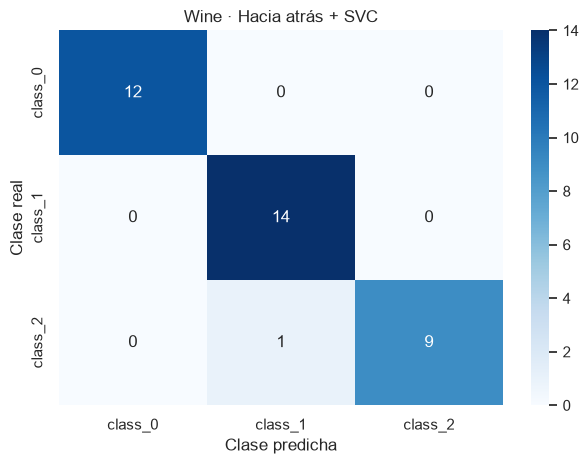

In [68]:
sns.heatmap(
    matrix, annot=True, fmt="d", cmap="Blues",
    xticklabels=wine.target_names, yticklabels=wine.target_names,
)
plt.title(f"Wine · {winner_selector} + {winner_name}")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

### Chuleta de técnicas

| Técnica | ¿Qué criterio usa? | ¿Necesita la clase? | Precaución principal |
|---|---|---|---|
| Varianza cero | Variación de cada columna | No | No elimina todas las variables poco útiles |
| Correlación | Redundancia lineal entre columnas | No | Depende del orden y del umbral |
| ANOVA | Separación individual entre clases | Sí | No evalúa combinaciones |
| Forward | Accuracy al incorporar una variable | Sí | No reconsidera incorporaciones anteriores |
| Backward | Accuracy al retirar una variable | Sí | Necesita muchos entrenamientos |
| RFE | Pesos del modelo y eliminación sucesiva | Sí | Depende del modelo que produce los pesos |
| Lasso | Coeficientes reducidos a cero | Sí | Depende del escalado y la regularización |
| Exhaustiva | Todos los subconjuntos de las candidatas | Sí | El costo crece exponencialmente |